In [ ]:
import os
import numpy as np
import pandas as pd
import umap
import seaborn as sns 
import matplotlib.pyplot as plt

c:\Users\jvill\anaconda3\envs\hsi_machine_learning\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### snRNA-seq data

In [2]:
sn_3712_path = r"C:\Users\jvill\Documents\integrated_pipeline\snRNA\umap_coordinates_3712.csv"
sn_3723_path = r"C:\Users\jvill\Documents\integrated_pipeline\snRNA\umap_coordinates_3723.csv" 

sn_3712_df = pd.read_csv(sn_3712_path)
sn_3723_df = pd.read_csv(sn_3723_path)

NameError: name 'pd' is not defined

In [4]:
sn_3712_df['sample'] = '3712'
sn_3723_df['sample'] = '3723'

In [5]:
sn_3712_df.head(5)

,Unnamed: 0,umap_1,umap_2,v2.subclass.l1,sample
0,PA10_AAACCCAAGAAGCGAA-1,6.535445,-1.055000,PC,3712
1,PA10_AAACCCAAGAGCCGTA-1,2.135303,11.388339,TAL,3712
2,PA10_AAACCCAAGATGCAGC-1,-0.244590,-0.772024,DTL,3712
3,PA10_AAACCCACAATAGTGA-1,2.480744,11.574912,TAL,3712
4,PA10_AAACCCACAATCGCCG-1,-1.947224,-13.664860,FIB,3712


In [6]:
sn_3723_df.head(5)

,Unnamed: 0,umap_1,umap_2,v2.subclass.l1,sample
0,KC125_AAACCCACAACACAAA-1,7.130124,1.667768,CNT,3723
1,KC125_AAACCCACAGTCGCAC-1,6.593482,0.286573,PC,3723
2,KC125_AAACCCAGTGCAACAG-1,7.362960,-0.313086,CNT,3723
3,KC125_AAACCCATCATATGGC-1,7.032190,2.476495,CNT,3723
4,KC125_AAACCCATCCAGGACC-1,-4.995205,0.547091,PT,3723


In [7]:
plot_df = pd.concat([sn_3712_df, sn_3723_df], axis=0)  

In [8]:
plot_df

,Unnamed: 0,umap_1,umap_2,v2.subclass.l1,sample
0,PA10_AAACCCAAGAAGCGAA-1,6.535445,-1.055000,PC,3712
1,PA10_AAACCCAAGAGCCGTA-1,2.135303,11.388339,TAL,3712
2,PA10_AAACCCAAGATGCAGC-1,-0.244590,-0.772024,DTL,3712
3,PA10_AAACCCACAATAGTGA-1,2.480744,11.574912,TAL,3712
4,PA10_AAACCCACAATCGCCG-1,-1.947224,-13.664860,FIB,3712
...,...,...,...,...,...
46675,KC128_TTTGTTGGTATTACCC-1,1.981963,11.053428,TAL,3723
46676,KC128_TTTGTTGGTCAAAGGG-1,7.811531,0.543554,CNT,3723
46677,KC128_TTTGTTGGTGAGCGAA-1,3.688562,10.067319,TAL,3723
46678,KC128_TTTGTTGGTGATGAGG-1,-5.301616,4.290937,PT,3723


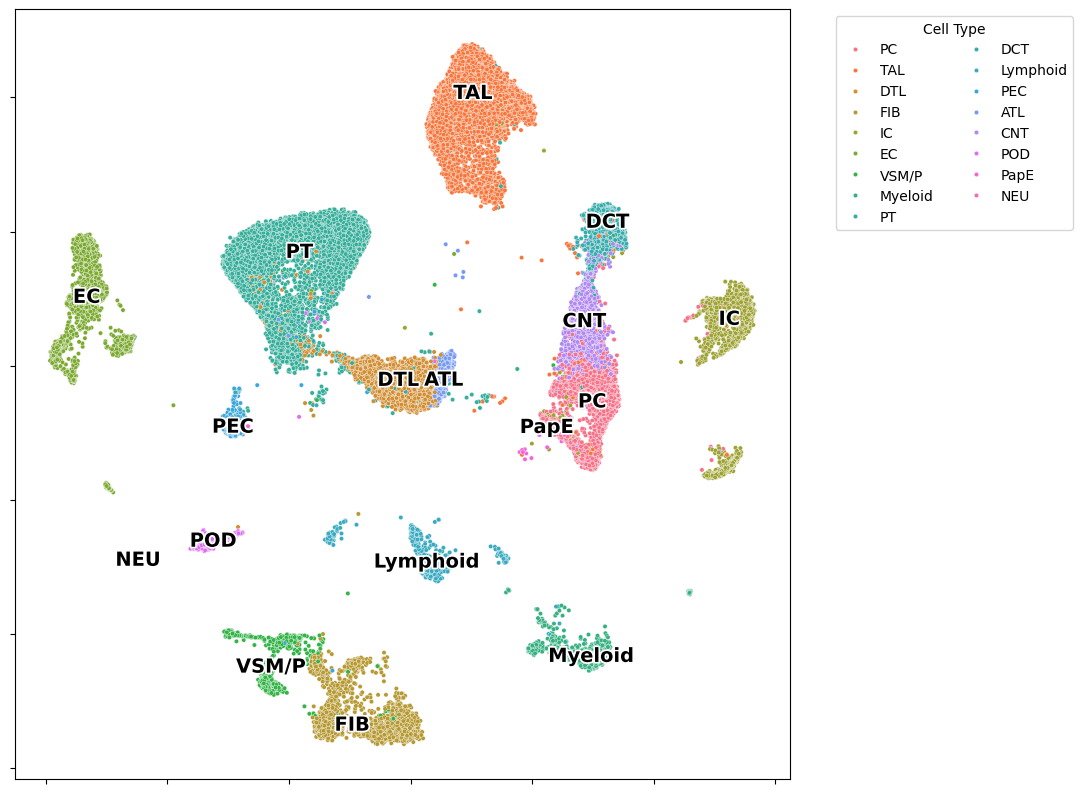

In [ ]:
import matplotlib.patheffects as pe
fig, ax = plt.subplots(figsize=(10, 10))

plot_df = plot_df[plot_df['v2.subclass.l1'].isin(plot_df['v2.subclass.l1'].value_counts()[plot_df['v2.subclass.l1'].value_counts() > 3].index)]

sns.scatterplot(
    data=plot_df, 
    x='umap_1', 
    y='umap_2', 
    hue='v2.subclass.l1', 
    s=10,
    )
embeddings = plot_df[['umap_1', 'umap_2']].values

labels = plot_df['v2.subclass.l1'].values
unique_labels = plot_df['v2.subclass.l1'].unique()
for label in unique_labels:
    mask = labels == label
    centroid_x = np.median(embeddings[mask, 0])
    centroid_y = np.median(embeddings[mask, 1])
    ax.text(centroid_x, centroid_y, label, fontsize=14, fontweight='bold',
            ha='center', va='center', color='black', path_effects=[pe.withStroke(linewidth=2.5, foreground='white')],
            zorder=100)



# ax.set_title('UMAP of snRNA-seq Data')
# ax.set_xlabel('UMAP 1')
# ax.set_ylabel('UMAP 2')

ax.set_xlabel('')
ax.set_ylabel('')

ax.set_xticklabels([])
ax.set_yticklabels([])

ax.legend(ncols=1 if len(plot_df['v2.subclass.l1'].unique()) < 5 else 2, title='Cell Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.savefig(r"C:\Users\jvill\Documents\integrated_pipeline\snRNA\umap_plot.png", bbox_inches='tight', dpi=300)

plt.show()

## CODEX UMAP Analysis

In [1]:
import os
import numpy as np
import pandas as pd
import umap
import seaborn as sns 
import matplotlib.pyplot as plt
Codex_path = r"C:\Users\jvill\/Documents\integrated_pipeline\WSI_data\CODEX\clusters-metadata\cluster_info_1.csv"
codex_df = pd.read_csv(Codex_path)
if 'Unnamed: 0' in codex_df.columns:
    codex_df = codex_df.drop(columns=['Unnamed: 0'])

# Normalize the mean values for each cluster
ab_columns = codex_df.columns[4:-7]
codex_df[ab_columns] = codex_df[ab_columns].apply(lambda x: (x - x.mean()) / x.std(), axis=0)

order =   { 
    "Glomeruli | Podo, CD31" : "Glomeruli | Podo, CD31",
    "PT | LRP2": "PT | LRP2",
    "PT | LRP2, CD90": "PT | LRP2, THY1",
    "PT | LRP2, PROM1,VCAM1": "PT | LRP2, PROM1, VCAM1",
    "TDL | AQP1, Cyto8 (N1)": "TDL | AQP1, Cyto8 (N1)",
    "TDL | AQP1, Cyto8 (N2)": "TDL | AQP1, Cyto8 (N2)",
    "TAL | NaK/UMOD": "TAL | NaK, UMOD",
    "TAL | UMOD (N1)": "TAL | UMOD",
    "DCT | SLC12a3": "DCT | SLC12a3",
    "DN | Cyto8 (N2)": "DN | Cyto8",
    "DN | Cyto8, Bcat": "DN | Cyto8, Bcat",
    "DN | Cyto8, Bcat, Ecad": "DN | Cyto8, Bcat, Ecad",
    "DN | Cyto8, Ecad": "DN | Cyto8, Ecad",
    "Endothelium | CD31,": "Endothelium | CD31",
    "Endothelium | CD31, Podo": "Endothelium | CD31, Podo",
    "Pericytes | CD90+, CD31 (-)": "Pericytes | CD90, CD31(-)",
    "VSMCs | aSMA": "VSMCs | aSMA",
    "Immune - MP | CD45, CD206": "Immune - MP | CD45, CD206",
    "Immune - T | CD3, CD4": "Immune - T | CD3, CD4",
    "Immune - T | CD3, CD8": "Immune - T | CD3, CD8",
    "Interstitial cells | IGFBP7": "Interstitial cells | IGFBP7"
}

codex_ab_columns = codex_df.iloc[:, 4:-7].columns
codex_df['Cluster_Name'] = codex_df['Cluster_Name'].map(order)
heatmap_order = list(order.values())

mean_df = codex_df.groupby('Cluster_Name')[codex_ab_columns].mean().reset_index()
mean_df['Cluster_Name'] = pd.Categorical(mean_df['Cluster_Name'], categories=heatmap_order, ordered=True)
mean_df = mean_df.sort_values('Cluster_Name')

c:\Users\jvill\anaconda3\envs\hsi_machine_learning\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


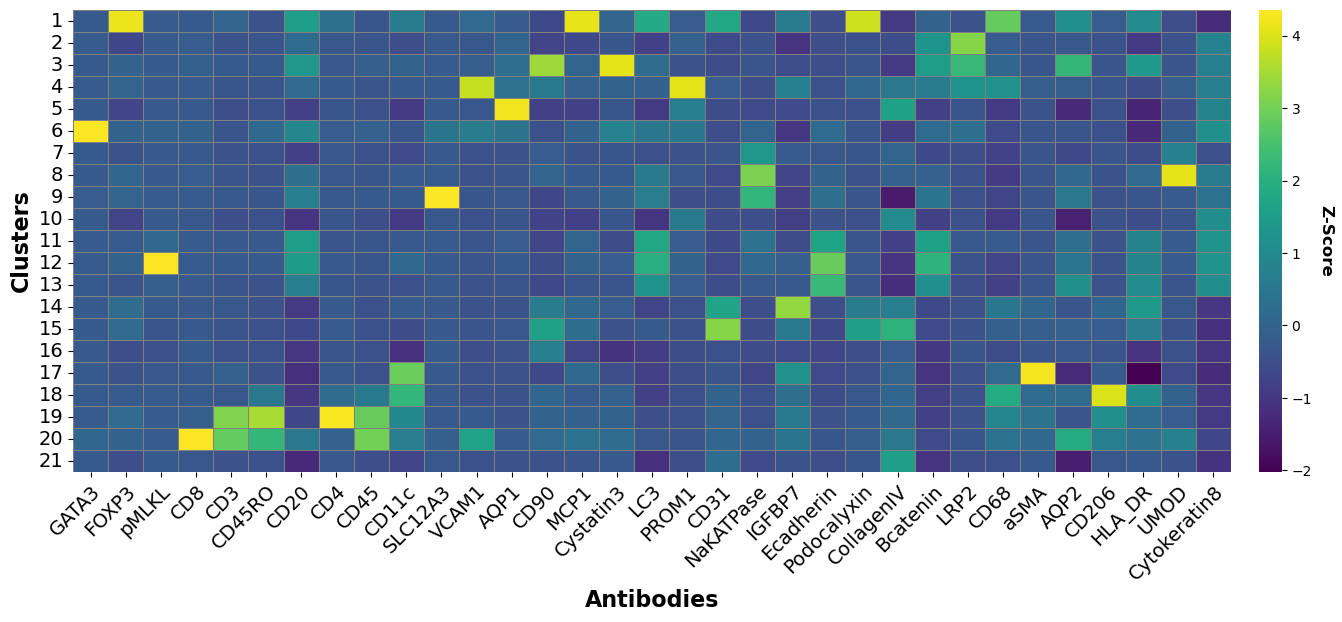

In [6]:
fig, ax = plt.subplots(figsize=(18, 6))

# Z-scale the mean values for better heatmap visualization
heatmap_data = mean_df.iloc[:, 1:].copy()
heatmap_data = (heatmap_data - heatmap_data.mean()) / heatmap_data.std()

cluster_indeces = [idx for idx, row in enumerate(mean_df['Cluster_Name'].unique(), start=1)]


ax = sns.heatmap(heatmap_data, 
            cmap='viridis', 
            yticklabels=mean_df['Cluster_Name'],
            linewidths=0.5,
            linecolor='gray', cbar=True,
            ax=ax,  cbar_kws={'pad': 0.02})
cbar = ax.collections[0].colorbar
cbar.set_label('Z-Score', size=12, rotation=270, labelpad=15, fontweight='bold')
ax.set_xticklabels(mean_df.columns[1:], rotation=45, ha='right', fontsize=14, rotation_mode='anchor')
ax.set_yticklabels(cluster_indeces, rotation=0, fontsize=14)
# ax.set_title('Normalized Marker Expression by Cluster', fontsize=20, fontweight='bold')
ax.set_xlabel('Antibodies', fontsize=16, fontweight='bold')
ax.set_ylabel('Clusters', fontsize=16, fontweight='bold')

plt.savefig(r"C:\Users\jvill\Documents\integrated_pipeline\WSI_data\CODEX\clusters-metadata\cluster_marker_heatmap.png", bbox_inches='tight', dpi=300, transparent=True)

plt.show()

In [4]:
cluster_indeces

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]